In [14]:
import kagglehub
from kagglehub import KaggleDatasetAdapter

# Download latest version
path = kagglehub.dataset_download("tawsifurrahman/tuberculosis-tb-chest-xray-dataset")

print("Path to dataset files:", path)

# Install dependencies as needed:
# pip install kagglehub[pandas-datasets]


# Set the path to the file you'd like to load


Using Colab cache for faster access to the 'tuberculosis-tb-chest-xray-dataset' dataset.
Path to dataset files: /kaggle/input/tuberculosis-tb-chest-xray-dataset


In [15]:
import torch
from torchvision import models, transforms
from PIL import Image

# Load pretrained model (auto-downloads weights)
model = models.mobilenet_v3_large(weights="DEFAULT")
model.eval()

# Modify for binary classification (TB vs non-TB)
model.classifier[3] = torch.nn.Linear(model.classifier[3].in_features, 1)

print(model)


MobileNetV3(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(16, eps=0.001, momentum=0.01, affine=True, track_running_stats=True)
      (2): Hardswish()
    )
    (1): InvertedResidual(
      (block): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=16, bias=False)
          (1): BatchNorm2d(16, eps=0.001, momentum=0.01, affine=True, track_running_stats=True)
          (2): ReLU(inplace=True)
        )
        (1): Conv2dNormActivation(
          (0): Conv2d(16, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (1): BatchNorm2d(16, eps=0.001, momentum=0.01, affine=True, track_running_stats=True)
        )
      )
    )
    (2): InvertedResidual(
      (block): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(16, 64, kernel_size=(1, 1), stride=(1, 1), bi

In [16]:
# Data Augmentation
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.Grayscale(num_output_channels=3),

    transforms.RandomRotation(10),
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),

    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406],
                         [0.229, 0.224, 0.225])
])

val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])



### Explanation of Data Augmentation Transforms for TB CXR Detection

Data augmentation is a powerful technique used to increase the diversity of the training dataset, which helps in improving the model's generalization capabilities and reducing overfitting, especially crucial in medical imaging where datasets can be limited.

#### Training Transforms (`train_transform`):

These transforms are applied to the training images to introduce variability:

1.  **`transforms.Resize((224, 224))`**: This resizes all images to a consistent size of 224x224 pixels. This is a standard input size for many pre-trained convolutional neural networks (like MobileNetV3 used here), ensuring compatibility and uniform processing.

2.  **`transforms.Grayscale(num_output_channels=3)`**: Although X-ray images are typically grayscale, many pre-trained models expect 3-channel (RGB) input. This transform converts the single-channel grayscale image into a 3-channel image by simply duplicating the grayscale channel, making it compatible with the pre-trained MobileNetV3 model.

3.  **`transforms.RandomRotation(10)`**: Randomly rotates the image by a small degree (up to 10 degrees in either direction). In real-world scenarios, X-rays might not always be perfectly aligned, or patients might be positioned slightly differently. This augmentation helps the model become invariant to minor rotational changes.

4.  **`transforms.RandomResizedCrop(224, scale=(0.8, 1.0))`**: This randomly crops a portion of the image and then resizes it to 224x224. The `scale` parameter means the cropped area will be between 80% and 100% of the original image's area. This simulates variations in patient positioning or focus within the X-ray, encouraging the model to learn features that are robust to different scales and views of the chest.

5.  **`transforms.ColorJitter(brightness=0.2, contrast=0.2)`**: Randomly changes the brightness and contrast of the image. X-ray images can vary in intensity, exposure, and overall quality due to different machines, settings, or processing techniques. This augmentation helps the model become robust to these common variations.

6.  **`transforms.ToTensor()`**: Converts the PIL Image or NumPy array into a PyTorch `Tensor`. It also scales the pixel intensity values from the range `[0, 255]` to `[0.0, 1.0]`.

7.  **`transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])`**: Normalizes the tensor image with a given mean and standard deviation for each channel. These specific values (ImageNet means and standard deviations) are commonly used when working with models pre-trained on the ImageNet dataset, as it helps the model utilize the learned features effectively by aligning the input distribution.

#### Validation Transforms (`val_transform`):

These transforms are applied to the validation images. Note that validation transforms are *deterministic* and do not include random augmentations, as we want to evaluate the model on a consistent, representative test set:

1.  **`transforms.Resize((224, 224))`**: Same as for training, ensures consistent input size.
2.  **`transforms.Grayscale(num_output_channels=3)`**: Same as for training, for model compatibility.
3.  **`transforms.ToTensor()`**: Same as for training, converts to tensor and scales pixel values.
4.  **`transforms.Normalize(...)`**: Same as for training, normalizes pixel values using ImageNet statistics.


In [17]:
from torchvision import datasets
from sklearn.model_selection import train_test_split
from torch.utils.data import Subset

# 1. Load dataset ONCE with transform (important)
dataset = datasets.ImageFolder(
    path + "/TB_Chest_Radiography_Database",
    transform=train_transform  # temporary, we'll override later
)

# 2. Create indices
indices = list(range(len(dataset)))

train_idx, val_idx = train_test_split(
    indices,
    test_size=0.2,
    random_state=42,
    stratify=dataset.targets
)

# 3. Create separate datasets with correct transforms
train_dataset = datasets.ImageFolder(
    path + "/TB_Chest_Radiography_Database",
    transform=train_transform
)

val_dataset = datasets.ImageFolder(
    path + "/TB_Chest_Radiography_Database",
    transform=val_transform
)

# 4. Apply correct subsets
train_dataset = Subset(train_dataset, train_idx)
val_dataset = Subset(val_dataset, val_idx)

In [18]:
!pip install imagehash
intersection = set(train_idx) & set(val_idx)
print(len(intersection))

print(train_dataset.dataset is val_dataset.dataset)

train_paths = set([dataset.imgs[i][0] for i in train_idx])
val_paths = set([dataset.imgs[i][0] for i in val_idx])

print(len(train_paths & val_paths))

from PIL import Image
import imagehash

def get_hash(path):
    return imagehash.phash(Image.open(path))

train_hashes = set(get_hash(dataset.imgs[i][0]) for i in train_idx)
val_hashes = set(get_hash(dataset.imgs[i][0]) for i in val_idx)

print(len(train_hashes & val_hashes))

0
False
0
3


In [19]:
import imagehash
from PIL import Image

batch_size = 32
num_epochs = 10

# 1. Identify hashes of images in the training set
train_hashes = set(get_hash(dataset.imgs[i][0]) for i in train_idx)

# 2. Filter val_idx to exclude images that have a hash existing in the training set
clean_val_idx = []
removed_count = 0

for i in val_idx:
    h = get_hash(dataset.imgs[i][0])
    if h in train_hashes:
        removed_count += 1
    else:
        clean_val_idx.append(i)

print(f"Removed {removed_count} duplicate/overlapping images from validation set.")
print(f"New validation set size: {len(clean_val_idx)}")

# 3. Re-create the validation subset and loader
from torch.utils.data import Subset

# Use the clean indices
val_dataset = Subset(datasets.ImageFolder(path + '/TB_Chest_Radiography_Database', transform=val_transform), clean_val_idx)

# Update the loader
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

print("val_loader updated successfully.")

Removed 3 duplicate/overlapping images from validation set.
New validation set size: 837
val_loader updated successfully.


In [20]:
import torch.optim as optim
import torch

num_normal = 2800
num_tb = 560

pos_weight = torch.tensor([num_normal / num_tb]).to(device)

criterion = torch.nn.BCEWithLogitsLoss(pos_weight=pos_weight)

optimizer = optim.Adam(model.parameters(), lr=0.0001)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', patience=2, factor=0.1
)

print(f"Loss function initialized with TB weight: {pos_weight.item():.2f}")

Loss function initialized with TB weight: 5.00


In [21]:
import numpy as np


train_labels = [train_dataset.dataset.targets[i] for i in train_dataset.indices]

counts = np.bincount(train_labels)
print(f"Class 0 (Normal): {counts[0]}")
print(f"Class 1 (TB): {counts[1]}")

Class 0 (Normal): 2800
Class 1 (TB): 560


In [22]:
import torch
from sklearn.metrics import precision_score, recall_score, f1_score
import numpy as np

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model.to(device)

num_epochs = 10
batch_size = 32
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
best_recall = 0

for epoch in range(num_epochs):
    model.train()
    train_loss = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.float().unsqueeze(1).to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        train_loss += loss.item()

    train_loss /= len(train_loader)

    model.eval()
    val_loss = 0
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device).float().unsqueeze(1)

            outputs = model(images)
            loss = criterion(outputs, labels)
            val_loss += loss.item()

            probs = torch.sigmoid(outputs)
            preds = (probs > 0.5).float()

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    val_loss /= len(val_loader)

    # Calculate Metrics
    all_preds = np.array(all_preds)
    all_labels = np.array(all_labels)

    accuracy = (all_preds == all_labels).mean()
    precision = precision_score(all_labels, all_preds, zero_division=0)
    recall = recall_score(all_labels, all_preds, zero_division=0)
    f1 = f1_score(all_labels, all_preds, zero_division=0)

    scheduler.step(val_loss)
    if recall > best_recall:
      best_recall = recall
      torch.save({
          "epoch": epoch,
          "model_state_dict": model.state_dict(),
          "optimizer_state_dict": optimizer.state_dict(),
          "scheduler_state_dict": scheduler.state_dict(),
          "best_recall": best_recall
      }, "best_model.pth")

    print(f"Epoch {epoch+1}/{num_epochs}")
    print(f"Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f}")
    print(f"Acc: {accuracy:.4f} | Prec: {precision:.4f} | Recall: {recall:.4f} | F1: {f1:.4f}")
    print("-" * 30)

Epoch 1/10
Train Loss: 0.3345 | Val Loss: 0.4397
Acc: 0.9677 | Prec: 1.0000 | Recall: 0.8029 | F1: 0.8907
------------------------------
Epoch 2/10
Train Loss: 0.0669 | Val Loss: 0.0527
Acc: 0.9940 | Prec: 0.9783 | Recall: 0.9854 | F1: 0.9818
------------------------------
Epoch 3/10
Train Loss: 0.0429 | Val Loss: 0.0498
Acc: 0.9952 | Prec: 0.9926 | Recall: 0.9781 | F1: 0.9853
------------------------------
Epoch 4/10
Train Loss: 0.0406 | Val Loss: 0.0529
Acc: 0.9952 | Prec: 1.0000 | Recall: 0.9708 | F1: 0.9852
------------------------------
Epoch 5/10
Train Loss: 0.0160 | Val Loss: 0.0514
Acc: 0.9964 | Prec: 1.0000 | Recall: 0.9781 | F1: 0.9889
------------------------------
Epoch 6/10
Train Loss: 0.0163 | Val Loss: 0.0242
Acc: 0.9988 | Prec: 1.0000 | Recall: 0.9927 | F1: 0.9963
------------------------------
Epoch 7/10
Train Loss: 0.0111 | Val Loss: 0.0713
Acc: 0.9964 | Prec: 1.0000 | Recall: 0.9781 | F1: 0.9889
------------------------------
Epoch 8/10
Train Loss: 0.0129 | Val Loss:

In [23]:
# 1. Load the best weights
checkpoint = torch.load('best_model.pth', map_location=device)
model.load_state_dict(checkpoint['model_state_dict'])
model.eval()

# 2. Trace the model using TorchScript for better portability (Deployment)
# We use a dummy input to trace the execution path
dummy_input = torch.randn(1, 3, 224, 224).to(device)
traced_model = torch.jit.trace(model, dummy_input)

# 3. Save the traced model
traced_model.save('tb_model_final.pt')

# 4. Also save the state_dict for standard PyTorch loading if needed
torch.save(model.state_dict(), 'deploy_model.pth')

print('Deployable model saved as tb_model_final.pt (TorchScript) and deploy_model.pth (Weights).')


Deployable model saved as tb_model_final.pt (TorchScript) and deploy_model.pth (Weights).


In [25]:
model.eval()

correct = 0
total = 0

all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)
        labels = labels.to(device).float().unsqueeze(1)

        outputs = model(images)

        probs = torch.sigmoid(outputs)
        preds = (probs > 0.5).float()

        correct += (preds == labels).sum().item()
        total += labels.numel()

        all_preds.append(preds.cpu())
        all_labels.append(labels.cpu())

accuracy = correct / total

print(f"Validation Accuracy: {accuracy:.4f}")

Validation Accuracy: 0.9988


In [26]:
from sklearn.metrics import confusion_matrix, classification_report
import torch

y_pred = torch.cat(all_preds).numpy()
y_true = torch.cat(all_labels).numpy()

print("Confusion Matrix:")
print(confusion_matrix(y_true, y_pred))

print("\nReport:")
print(classification_report(y_true, y_pred, target_names=["Normal", "TB"]))

Confusion Matrix:
[[700   0]
 [  1 136]]

Report:
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00       700
          TB       1.00      0.99      1.00       137

    accuracy                           1.00       837
   macro avg       1.00      1.00      1.00       837
weighted avg       1.00      1.00      1.00       837



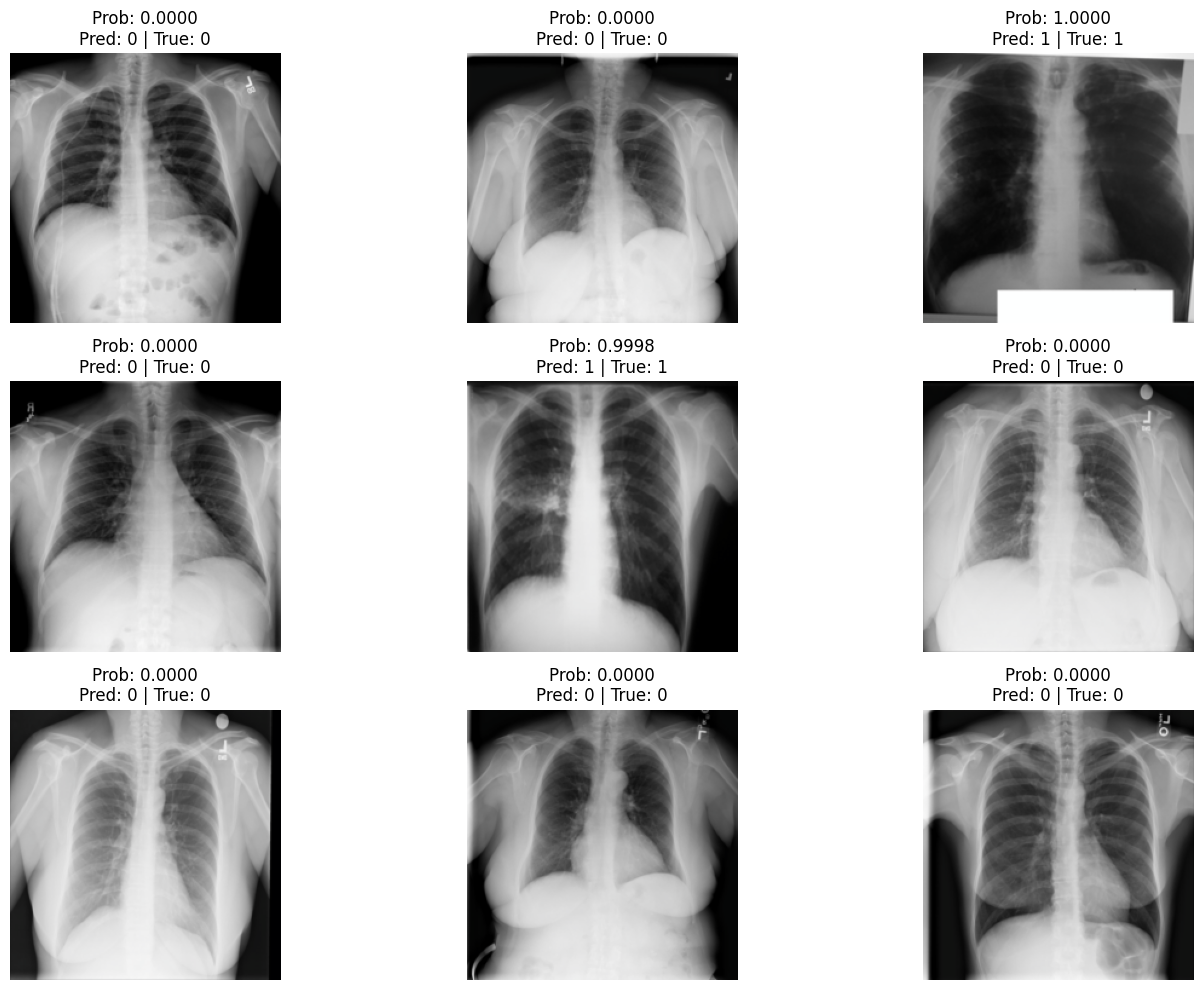

In [ ]:
import matplotlib.pyplot as plt
import random

# Set model to eval mode
model.eval()

# Randomly pick 9 indices from the validation dataset
sample_indices = random.sample(range(len(val_dataset)), 9)

plt.figure(figsize=(15, 10))

for i, idx in enumerate(sample_indices):
    # Get image and label
    image, label = val_dataset[idx]
    image_tensor = image.unsqueeze(0).to(device)

    with torch.no_grad():
        output = model(image_tensor)
        prob = torch.sigmoid(output).item()
        pred = 1 if prob > 0.5 else 0

    # Unnormalize for display
    img_display = image.permute(1, 2, 0).numpy()
    img_display = img_display * [0.229, 0.224, 0.225] + [0.485, 0.456, 0.406]
    img_display = img_display.clip(0, 1)

    plt.subplot(3, 3, i + 1)
    plt.imshow(img_display)
    plt.title(f"Prob: {prob:.4f}\nPred: {pred} | True: {int(label)}")
    plt.axis("off")

plt.tight_layout()
plt.show()